In [7]:
%pip install qiskit qiskit_aer pylatexenc
%pip install matplotlib

In [8]:
# import the necessary libraries
from qiskit import QuantumCircuit
from qiskit import transpile
from qiskit.visualization import plot_histogram
from qiskit_aer import Aer

In [9]:
# create a quantum circuit with 2 qubits
qc = QuantumCircuit(2)


In [10]:
# # un-comment the lines to make the |1> as initial state
# initial_state = [0,1]
# qc.initialize(initial_state, 0)

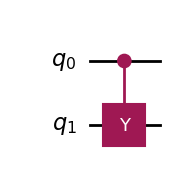

In [11]:
# apply quantum gates to the qubits
# qc.x(0)  # apply X gate to the qubit, which flips the state from |0> to |1>
# qc.h(0)  # apply H gate to the qubit, which creates a superposition state

# qc.cx(0, 1)  # apply CNOT gate to the qubits, which entangles them
qc.cy(0, 1)  # apply CY gate to the qubits, which creates a controlled superposition state
# qc.cz(0, 1)  # apply CH gate to the qubits, which creates a controlled superposition state

# qc.cs(0, 1)  # apply CS gate to the qubits, which creates a controlled superposition state

# apply controlled T gate to the qubits
# from qiskit.circuit.library import TGate
# ct_gate = TGate().control(1)  # create a controlled T gate
# qc.append(ct_gate, [0, 1])  # apply controlled T gate to the

# qc.swap(0, 1)  # apply SWAP gate to the qubits, which swaps their states

qc.draw('mpl')  # using matplotlib library, draw the quantum circuit

{'00': 1024}


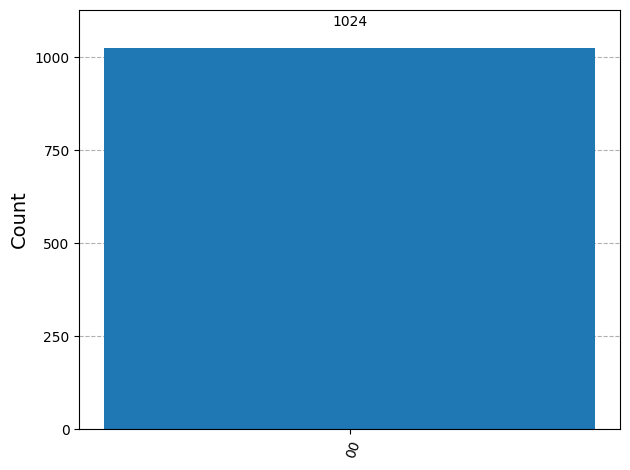

In [12]:
# add measurement to all the qubits
# from qiskit import transpile


qc.measure_all()
# using QASM simulator, simulate a real quantum computer measurement
backend = Aer.get_backend('qasm_simulator')

# Convert unsupported gates into simulator-supported gates
qc_transpiled = transpile(qc, backend)

job = backend.run(qc_transpiled, shots=1024)

counts = job.result().get_counts()

# job = backend.run(qc, shots=1024)
# counts = job.result().get_counts()
print(counts)
plot_histogram(counts)